<a href="https://colab.research.google.com/github/miriamamin1213-ux/ValidationSET/blob/main/HecktorANN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using device: cpu
Mounted at /content/drive


Downloading...
From: https://drive.google.com/uc?id=1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv
To: /content/HPV2025.xlsx
100%|██████████| 66.0k/66.0k [00:00<00:00, 26.3MB/s]


Rows: 588 | Original predictors: 8
Predictors: ['Age', 'Gender', 'Tobacco Consumption', 'Alcohol Consumption', 'Performance Status', 'T-stage', 'N-stage', 'M-stage']
Train: 381 | Validation: 89 | Test: 118
Train class counts: {0: 37, 1: 344}
Validation class counts: {0: 9, 1: 80}
Test class counts: {0: 12, 1: 106}
Original predictor count: 8
Encoded feature count: 15
Automatic class weights: [5.14864865 0.55377907]
SMOTE: False
Epoch 001/500 | train loss=0.6902 | val loss=0.7081 | val ROC-AUC=0.7028 | val PR-AUC=0.9404 | val balanced accuracy=0.6840
Epoch 025/500 | train loss=0.4239 | val loss=0.5990 | val ROC-AUC=0.7958 | val PR-AUC=0.9687 | val balanced accuracy=0.7944
Epoch 050/500 | train loss=0.3477 | val loss=0.7504 | val ROC-AUC=0.7514 | val PR-AUC=0.9635 | val balanced accuracy=0.7569
Epoch 075/500 | train loss=0.2991 | val loss=0.8915 | val ROC-AUC=0.7347 | val PR-AUC=0.9607 | val balanced accuracy=0.7139
Epoch 100/500 | train loss=0.2731 | val loss=1.1319 | val ROC-AUC=0.7236

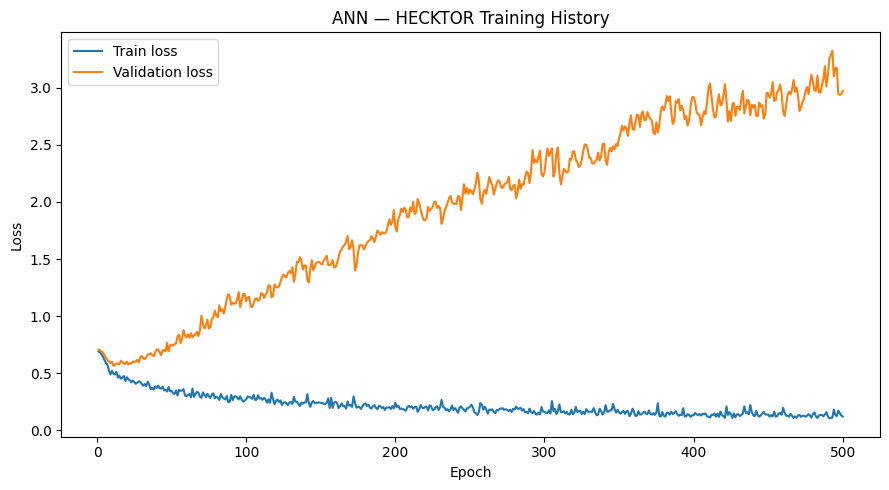


CHECKPOINT: best_val_loss 
Epoch: 11 
Validation-selected threshold: 0.52 
TEST METRICS
 Dataset                               HECKTOR
Model                                     ANN
Checkpoint                      best_val_loss
Checkpoint_Epoch                           11
Validation_Loss                      0.566002
Validation_ROC_AUC                   0.822222
Validation_PR_AUC                    0.977952
Validation_Balanced_Accuracy         0.776389
Threshold                                0.52
Accuracy                             0.737288
Balanced_Accuracy                    0.705975
Precision                            0.951807
Recall                               0.745283
F1                                   0.835979
ROC_AUC                              0.761006
PR_AUC                               0.953553 
Confusion matrix:
 [[ 8  4]
 [27 79]] 
Classification report:
               precision    recall  f1-score   support

           0     0.2286    0.6667    0.3404        12
 

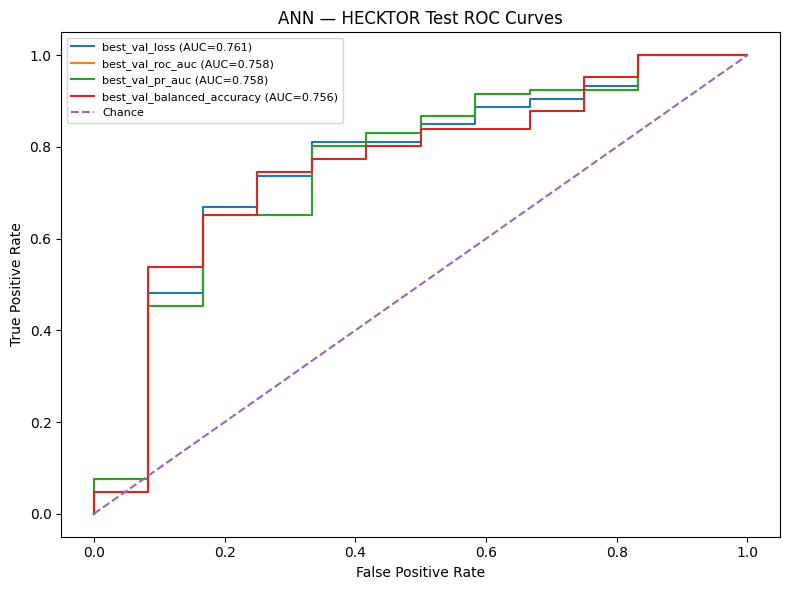

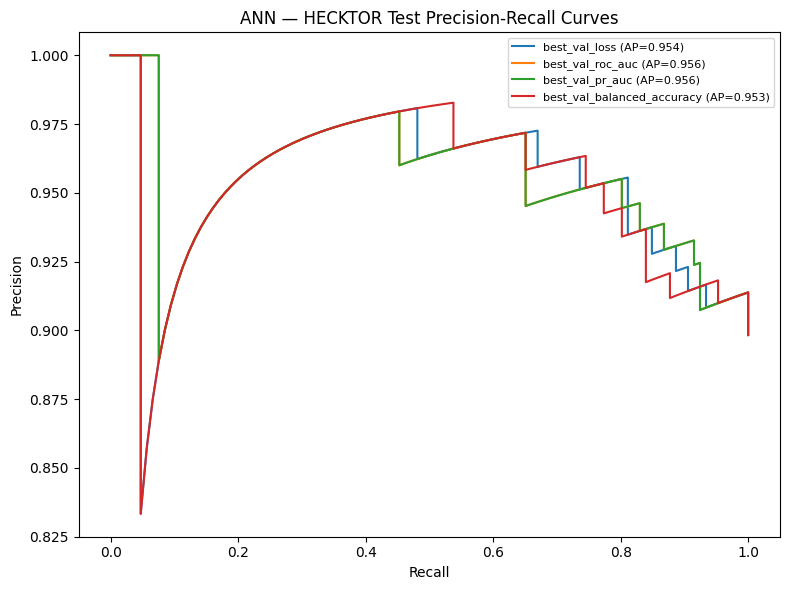


HECKTOR ANN — CHECKPOINT COMPARISON — TEST SET
Dataset Model                 Checkpoint  Checkpoint_Epoch  Threshold  Accuracy  Balanced_Accuracy  Precision   Recall       F1  ROC_AUC   PR_AUC
HECKTOR   ANN              best_val_loss                11      0.520  0.737288           0.705975   0.951807 0.745283 0.835979 0.761006 0.953553
HECKTOR   ANN           best_val_roc_auc                 7      0.515  0.754237           0.715409   0.952941 0.764151 0.848168 0.757862 0.955910
HECKTOR   ANN            best_val_pr_auc                 7      0.515  0.754237           0.715409   0.952941 0.764151 0.848168 0.757862 0.955910
HECKTOR   ANN best_val_balanced_accuracy                27      0.660  0.745763           0.747642   0.963415 0.745283 0.840426 0.755503 0.953275

Saved results to: /content/drive/MyDrive/ANN_results_HECKTOR
Saved checkpoints to: /content/drive/MyDrive/ANN_results_HECKTOR/checkpoints
Output files:
 - ann_hecktor_preprocessor.joblib
 - checkpoint_summary.csv
 - metri

In [1]:
# ============================================================
# ANN — HECKTOR HPV CLASSIFIER | HANCOCK-ALIGNED | SEED 42 | NO SMOTE
# 500 Epochs | Train/Validation/Test | Four Validation-Selected Checkpoints
# ============================================================
import os,json,random,copy,warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import joblib
from torch.utils.data import TensorDataset,DataLoader
from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.metrics import accuracy_score,balanced_accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,confusion_matrix,classification_report,roc_curve,precision_recall_curve
warnings.filterwarnings("ignore",category=FutureWarning)
SEED=42
MAX_EPOCHS=500
BATCH_SIZE=32
# ------------------------------------------------------------
# 1. REPRODUCIBILITY, DEVICE AND DATA LOADING
# ------------------------------------------------------------
def seed_everything(seed=42):
    os.environ["PYTHONHASHSEED"]=str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"]=":4096:8"
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic=True
    torch.backends.cudnn.benchmark=False
    torch.backends.cuda.matmul.allow_tf32=False
    torch.backends.cudnn.allow_tf32=False
    torch.use_deterministic_algorithms(True,warn_only=True)
seed_everything(SEED)
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:",device)
drive.mount("/content/drive")
# ------------------------------------------------------------
# 2. LOAD HECKTOR DATA AND SELECT EIGHT PREDICTORS
# ------------------------------------------------------------
import subprocess,sys
try:
    import gdown
except ImportError:
    subprocess.check_call([sys.executable,"-m","pip","install","-q","gdown"])
    import gdown
DATA_PATH="/content/HPV2025.xlsx"
if not os.path.exists(DATA_PATH):
    gdown.download(id="1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv",output=DATA_PATH,quiet=False)
BASE="/content/drive/MyDrive"
OUT_DIR=os.path.join(BASE,"ANN_results_HECKTOR")
CHECKPOINT_DIR=os.path.join(OUT_DIR,"checkpoints")
os.makedirs(CHECKPOINT_DIR,exist_ok=True)
df=pd.read_excel(DATA_PATH)
if "HPV Status" not in df.columns: raise KeyError("Missing target column: HPV Status")
df=df.dropna(subset=["HPV Status"]).copy()
features=["Age","Gender","Tobacco Consumption","Alcohol Consumption","Performance Status","T-stage","N-stage","M-stage"]
cat_cols=["Gender","Tobacco Consumption","Alcohol Consumption","Performance Status"]
num_cols=["Age","T-stage","N-stage","M-stage"]
required=features+["HPV Status"]
missing=[c for c in required if c not in df.columns]
if missing: raise KeyError(f"Missing required columns: {missing}")
df=df[required].copy()
for col,mapping in {"T-stage":{"T0":0,"T1":1,"T2":2,"T3":3,"T4":4},"N-stage":{"N0":0,"N1":1,"N2":2,"N3":3},"M-stage":{"M0":0,"M1":1}}.items():
    df[col]=df[col].replace(mapping)
def normalize_label(v):
    if pd.isna(v): return np.nan
    s=str(v).strip().lower()
    if s in {"0","0.0","negative","neg","false","no"}: return 0
    if s in {"1","1.0","positive","pos","true","yes"}: return 1
    try:
        n=float(s)
        if n in (0.0,1.0): return int(n)
    except (ValueError,TypeError): pass
    return np.nan
df["HPV_Label"]=df["HPV Status"].map(normalize_label)
df=df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"]=df["HPV_Label"].astype(int)
if set(df["HPV_Label"].unique())!={0,1}: raise ValueError("HPV Status must contain both binary classes coded as 0 and 1, or recognised positive/negative labels.")
df=df[features+["HPV_Label"]].reset_index(drop=True)
print("Rows:",len(df),"| Original predictors:",len(features))
print("Predictors:",features)
# ------------------------------------------------------------
# 3. STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# ------------------------------------------------------------
train_val,test=train_test_split(df,test_size=0.20,random_state=SEED,stratify=df["HPV_Label"])
train,val=train_test_split(train_val,test_size=0.1875,random_state=SEED,stratify=train_val["HPV_Label"])
train,val,test=[x.reset_index(drop=True) for x in (train,val,test)]
print("Train:",len(train),"| Validation:",len(val),"| Test:",len(test))
for name,part in [("Train",train),("Validation",val),("Test",test)]:
    print(f"{name} class counts:",part["HPV_Label"].value_counts().sort_index().to_dict())
# ------------------------------------------------------------
# 4. TRAIN-ONLY IMPUTATION, ONE-HOT ENCODING AND SCALING
# ------------------------------------------------------------
X_train_df=train[features].copy()
X_val_df=val[features].copy()
X_test_df=test[features].copy()
for frame in [X_train_df,X_val_df,X_test_df]:
    for col in num_cols: frame[col]=pd.to_numeric(frame[col],errors="coerce")
for col in num_cols:
    median=X_train_df[col].median()
    if pd.isna(median): median=0.0
    for frame in [X_train_df,X_val_df,X_test_df]: frame[col]=frame[col].fillna(median)
for col in cat_cols:
    for frame in [X_train_df,X_val_df,X_test_df]:
        frame[col]=frame[col].astype("object").replace(r"^\s*$",np.nan,regex=True).replace(["nan","None","NaN"],np.nan)
    modes=X_train_df[col].mode(dropna=True)
    fill_value=str(modes.iloc[0]) if not modes.empty else "Unknown"
    for frame in [X_train_df,X_val_df,X_test_df]:
        frame[col]=frame[col].fillna(fill_value).astype(str).replace(["","nan","None","NaN"],"Unknown")
try: encoder=OneHotEncoder(handle_unknown="ignore",sparse_output=False)
except TypeError: encoder=OneHotEncoder(handle_unknown="ignore",sparse=False)
preprocessor=ColumnTransformer([("num",StandardScaler(),num_cols),("cat",encoder,cat_cols)])
X_train=preprocessor.fit_transform(X_train_df).astype(np.float32)
X_val=preprocessor.transform(X_val_df).astype(np.float32)
X_test=preprocessor.transform(X_test_df).astype(np.float32)
y_train=train["HPV_Label"].to_numpy(dtype=np.int64)
y_val=val["HPV_Label"].to_numpy(dtype=np.int64)
y_test=test["HPV_Label"].to_numpy(dtype=np.int64)
print("Original predictor count:",len(features))
print("Encoded feature count:",X_train.shape[1])
# ------------------------------------------------------------
# 5. AUTOMATIC CLASS WEIGHTS — NO SMOTE
# ------------------------------------------------------------
counts=np.bincount(y_train,minlength=2)
if np.any(counts==0): raise ValueError("Both classes must be present in training data.")
weights=len(y_train)/(2.0*counts)
class_weights=torch.tensor(weights,dtype=torch.float32,device=device)
print("Automatic class weights:",weights)
print("SMOTE: False")
# ------------------------------------------------------------
# 6. DATA LOADERS AND TENSORS
# ------------------------------------------------------------
train_dataset=TensorDataset(torch.tensor(X_train,dtype=torch.float32),torch.tensor(y_train,dtype=torch.long))
train_loader=DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True,generator=torch.Generator().manual_seed(SEED))
X_val_t=torch.tensor(X_val,dtype=torch.float32,device=device)
y_val_t=torch.tensor(y_val,dtype=torch.long,device=device)
X_test_t=torch.tensor(X_test,dtype=torch.float32,device=device)
# ------------------------------------------------------------
# 7. HANCOCK-ALIGNED ANN ARCHITECTURE AND OPTIMISER
# ------------------------------------------------------------
class ANNClassifier(nn.Module):
    def __init__(self,input_dim):
        super().__init__()
        self.network=nn.Sequential(nn.Linear(input_dim,64),nn.ReLU(),nn.Dropout(0.30),nn.Linear(64,32),nn.ReLU(),nn.Dropout(0.20),nn.Linear(32,16),nn.ReLU(),nn.Linear(16,2))
    def forward(self,x): return self.network(x)
model=ANNClassifier(X_train.shape[1]).to(device)
criterion=nn.CrossEntropyLoss(weight=class_weights,reduction="none")
optimizer=torch.optim.Adam(model.parameters(),lr=0.001,weight_decay=1e-4)
# ------------------------------------------------------------
# 8. VALIDATION METRICS, THRESHOLD SELECTION AND CHECKPOINTS
# ------------------------------------------------------------
thresholds=np.linspace(0.10,0.90,161)
def select_threshold(y_true,probabilities):
    scores=[balanced_accuracy_score(y_true,(probabilities>=t).astype(int)) for t in thresholds]
    best_score=max(scores)
    best_threshold=min((t for t,s in zip(thresholds,scores) if np.isclose(s,best_score)),key=lambda t:abs(t-0.5))
    return float(best_threshold),float(best_score)
def predict_probabilities(model,X_tensor):
    model.eval()
    with torch.no_grad(): return torch.softmax(model(X_tensor),dim=1)[:,1].cpu().numpy()
def calculate_validation_metrics(model):
    probabilities=predict_probabilities(model,X_val_t)
    threshold,bal_acc=select_threshold(y_val,probabilities)
    roc_auc=roc_auc_score(y_val,probabilities) if len(np.unique(y_val))==2 else np.nan
    pr_auc=average_precision_score(y_val,probabilities)
    return {"val_probabilities":probabilities,"threshold":threshold,"balanced_accuracy":bal_acc,"roc_auc":float(roc_auc),"pr_auc":float(pr_auc)}
checkpoint_specs={"best_val_loss":{"filename":"ann_hecktor_best_val_loss.pt","direction":"min"},"best_val_roc_auc":{"filename":"ann_hecktor_best_val_roc_auc.pt","direction":"max"},"best_val_pr_auc":{"filename":"ann_hecktor_best_val_pr_auc.pt","direction":"max"},"best_val_balanced_accuracy":{"filename":"ann_hecktor_best_val_balanced_accuracy.pt","direction":"max"}}
best_values={"best_val_loss":float("inf"),"best_val_roc_auc":-float("inf"),"best_val_pr_auc":-float("inf"),"best_val_balanced_accuracy":-float("inf")}
best_epochs={}
history=[]
# ------------------------------------------------------------
# 9. TRAIN FOR ALL 500 EPOCHS — NO EARLY STOPPING
# ------------------------------------------------------------
for epoch in range(1,MAX_EPOCHS+1):
    model.train()
    running_loss=0.0
    seen=0
    for xb,yb in train_loader:
        xb,yb=xb.to(device),yb.to(device)
        optimizer.zero_grad()
        per_example_loss=criterion(model(xb),yb)
        loss=per_example_loss.mean()
        loss.backward()
        optimizer.step()
        running_loss+=per_example_loss.detach().sum().item()
        seen+=len(yb)
    train_loss=running_loss/max(seen,1)
    model.eval()
    with torch.no_grad(): val_loss=criterion(model(X_val_t),y_val_t).mean().item()
    vr=calculate_validation_metrics(model)
    row={"epoch":epoch,"train_loss":float(train_loss),"val_loss":float(val_loss),"val_roc_auc":vr["roc_auc"],"val_pr_auc":vr["pr_auc"],"val_balanced_accuracy":vr["balanced_accuracy"],"val_threshold":vr["threshold"]}
    history.append(row)
    checkpoint_scores={"best_val_loss":val_loss,"best_val_roc_auc":vr["roc_auc"],"best_val_pr_auc":vr["pr_auc"],"best_val_balanced_accuracy":vr["balanced_accuracy"]}
    checkpoint_values={"best_val_loss":float(val_loss),"best_val_roc_auc":vr["roc_auc"],"best_val_pr_auc":vr["pr_auc"],"best_val_balanced_accuracy":float(vr["balanced_accuracy"])}
    for key,spec in checkpoint_specs.items():
        score=checkpoint_scores[key]
        improved=score<best_values[key] if spec["direction"]=="min" else np.isfinite(score) and score>best_values[key]
        if improved:
            best_values[key]=float(score)
            best_epochs[key]=epoch
            torch.save({"epoch":epoch,"model_state_dict":copy.deepcopy(model.state_dict()),"validation_loss":float(val_loss),"validation_roc_auc":vr["roc_auc"],"validation_pr_auc":vr["pr_auc"],"validation_balanced_accuracy":vr["balanced_accuracy"],"validation_threshold":vr["threshold"]},os.path.join(CHECKPOINT_DIR,spec["filename"]))
    if epoch==1 or epoch%25==0:
        print(f"Epoch {epoch:03d}/{MAX_EPOCHS} | train loss={train_loss:.4f} | val loss={val_loss:.4f} | val ROC-AUC={vr['roc_auc']:.4f} | val PR-AUC={vr['pr_auc']:.4f} | val balanced accuracy={vr['balanced_accuracy']:.4f}")
if len(history)!=MAX_EPOCHS: raise RuntimeError(f"Expected {MAX_EPOCHS} epochs, but ran {len(history)}.")
history_df=pd.DataFrame(history)
history_df.to_csv(os.path.join(OUT_DIR,"training_history.csv"),index=False)
print("Training completed:",len(history),"epochs")
print("Best checkpoint epochs:",best_epochs)
# ------------------------------------------------------------
# 10. SAVE TRAINING HISTORY PLOT
# ------------------------------------------------------------
plt.figure(figsize=(9,5))
plt.plot(history_df["epoch"],history_df["train_loss"],label="Train loss")
plt.plot(history_df["epoch"],history_df["val_loss"],label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN — HECKTOR Training History")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"training_history.png"),dpi=150)
plt.show()
# ------------------------------------------------------------
# 11. EVALUATE FOUR CHECKPOINTS ON THE HELD-OUT TEST SET
# ------------------------------------------------------------
all_test_metrics=[]
all_test_predictions=[]
checkpoint_summary=[]
for checkpoint_name,spec in checkpoint_specs.items():
    checkpoint_path=os.path.join(CHECKPOINT_DIR,spec["filename"])
    try: checkpoint=torch.load(checkpoint_path,map_location=device,weights_only=False)
    except TypeError: checkpoint=torch.load(checkpoint_path,map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    val_prob=predict_probabilities(model,X_val_t)
    test_prob=predict_probabilities(model,X_test_t)
    best_threshold,val_bal_acc=select_threshold(y_val,val_prob)
    test_pred=(test_prob>=best_threshold).astype(int)
    test_roc_auc=roc_auc_score(y_test,test_prob) if len(np.unique(y_test))==2 else np.nan
    test_pr_auc=average_precision_score(y_test,test_prob)
    metrics={"Dataset":"HECKTOR","Model":"ANN","Checkpoint":checkpoint_name,"Checkpoint_Epoch":int(checkpoint["epoch"]),"Validation_Loss":float(checkpoint["validation_loss"]),"Validation_ROC_AUC":float(checkpoint["validation_roc_auc"]),"Validation_PR_AUC":float(checkpoint["validation_pr_auc"]),"Validation_Balanced_Accuracy":float(val_bal_acc),"Threshold":float(best_threshold),"Accuracy":accuracy_score(y_test,test_pred),"Balanced_Accuracy":balanced_accuracy_score(y_test,test_pred),"Precision":precision_score(y_test,test_pred,zero_division=0),"Recall":recall_score(y_test,test_pred,zero_division=0),"F1":f1_score(y_test,test_pred,zero_division=0),"ROC_AUC":test_roc_auc,"PR_AUC":test_pr_auc}
    all_test_metrics.append(metrics)
    all_test_predictions.append(pd.DataFrame({"patient_index":test.index,"y_true":y_test,"probability_positive":test_prob,"prediction":test_pred,"checkpoint":checkpoint_name,"checkpoint_epoch":int(checkpoint["epoch"]),"threshold":best_threshold}))
    checkpoint_summary.append({k:metrics[k] for k in ["Dataset","Model","Checkpoint","Checkpoint_Epoch","Validation_Loss","Validation_ROC_AUC","Validation_PR_AUC","Validation_Balanced_Accuracy","Threshold"]})
    print("\n"+"="*65,"\nCHECKPOINT:",checkpoint_name,"\nEpoch:",checkpoint["epoch"],"\nValidation-selected threshold:",round(best_threshold,3),"\nTEST METRICS\n",pd.Series(metrics).to_string(),"\nConfusion matrix:\n",confusion_matrix(y_test,test_pred),"\nClassification report:\n",classification_report(y_test,test_pred,zero_division=0,digits=4))
metrics_df=pd.DataFrame(all_test_metrics)
metrics_df.to_csv(os.path.join(OUT_DIR,"metrics_all_checkpoints.csv"),index=False)
predictions_df=pd.concat(all_test_predictions,ignore_index=True)
predictions_df.to_csv(os.path.join(OUT_DIR,"test_predictions_all_checkpoints.csv"),index=False)
pd.DataFrame(checkpoint_summary).to_csv(os.path.join(OUT_DIR,"checkpoint_summary.csv"),index=False)
# ------------------------------------------------------------
# 12. SAVE TEST ROC AND PRECISION-RECALL CURVES
# ------------------------------------------------------------
plt.figure(figsize=(8,6))
for name,spec in checkpoint_specs.items():
    try: ckpt=torch.load(os.path.join(CHECKPOINT_DIR,spec["filename"]),map_location=device,weights_only=False)
    except TypeError: ckpt=torch.load(os.path.join(CHECKPOINT_DIR,spec["filename"]),map_location=device)
    model.load_state_dict(ckpt["model_state_dict"])
    prob=predict_probabilities(model,X_test_t)
    if len(np.unique(y_test))==2:
        fpr,tpr,_=roc_curve(y_test,prob)
        plt.plot(fpr,tpr,label=f"{name} (AUC={roc_auc_score(y_test,prob):.3f})")
plt.plot([0,1],[0,1],"--",label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ANN — HECKTOR Test ROC Curves")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"roc_curves_all_checkpoints.png"),dpi=150)
plt.show()
plt.figure(figsize=(8,6))
for name,spec in checkpoint_specs.items():
    try: ckpt=torch.load(os.path.join(CHECKPOINT_DIR,spec["filename"]),map_location=device,weights_only=False)
    except TypeError: ckpt=torch.load(os.path.join(CHECKPOINT_DIR,spec["filename"]),map_location=device)
    model.load_state_dict(ckpt["model_state_dict"])
    prob=predict_probabilities(model,X_test_t)
    precision,recall,_=precision_recall_curve(y_test,prob)
    plt.plot(recall,precision,label=f"{name} (AP={average_precision_score(y_test,prob):.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("ANN — HECKTOR Test Precision-Recall Curves")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"pr_curves_all_checkpoints.png"),dpi=150)
plt.show()
# ------------------------------------------------------------
# 13. SAVE PREPROCESSOR, SETTINGS AND COMPARISON METRICS
# ------------------------------------------------------------
joblib.dump(preprocessor,os.path.join(OUT_DIR,"ann_hecktor_preprocessor.joblib"))
settings={"dataset":"HECKTOR","model":"ANN","seed":SEED,"features":features,"removed_features":["RFS","Treatment","Relapse"],"target_column":"HPV Status","class_weights":weights.tolist(),"smote":False,"early_stopping":False,"max_epochs":MAX_EPOCHS,"epochs_run":len(history),"batch_size":BATCH_SIZE,"architecture":[len(features),64,32,16,2],"dropout":[0.30,0.20],"learning_rate":0.001,"weight_decay":1e-4,"optimizer":"Adam","encoding":"OneHotEncoder","numeric_features":num_cols,"categorical_features":cat_cols,"train_size":len(train),"validation_size":len(val),"test_size":len(test),"split":{"train":len(train),"validation":len(val),"test":len(test)},"checkpoint_epochs":{k:int(v) for k,v in best_epochs.items()},"checkpoint_files":{k:v["filename"] for k,v in checkpoint_specs.items()},"threshold_selection":"Maximize validation balanced accuracy; ties resolved by choosing threshold closest to 0.5","test_used_for_model_selection":False}
with open(os.path.join(OUT_DIR,"settings.json"),"w",encoding="utf-8") as f: json.dump(settings,f,indent=2)
# ------------------------------------------------------------
# 14. FINAL SUMMARY AND SAVED OUTPUTS
# ------------------------------------------------------------
display_columns=["Dataset","Model","Checkpoint","Checkpoint_Epoch","Threshold","Accuracy","Balanced_Accuracy","Precision","Recall","F1","ROC_AUC","PR_AUC"]
print("\n"+"="*100,"\nHECKTOR ANN — CHECKPOINT COMPARISON — TEST SET\n"+"="*100)
print(metrics_df[display_columns].to_string(index=False))
print("\nSaved results to:",OUT_DIR)
print("Saved checkpoints to:",CHECKPOINT_DIR)
print("Output files:")
for root,dirs,files in os.walk(OUT_DIR):
    for filename in sorted(files): print(" -",os.path.relpath(os.path.join(root,filename),OUT_DIR))